In [1]:
import shutil

shutil.copy("/Users/tushar/Documents/IIST/Sem-2/computer vision/Project/code/visual_mycode/runs/detect/train21/weights/best.pt", "best_model.pt")

'best_model.pt'

In [2]:
from ultralytics import YOLO

model = YOLO("best_model.pt")


image 1/1 /Users/tushar/Documents/IIST/Sem-2/computer vision/Project/code/visual_mycode/data/real/000.jpg: 448x640 2 black-bishops, 1 black-king, 2 black-knights, 6 black-pawns, 2 black-rooks, 2 white-bishops, 1 white-king, 2 white-knights, 6 white-pawns, 1 white-queen, 1 white-rook, 73.3ms
Speed: 1.5ms preprocess, 73.3ms inference, 0.3ms postprocess per image at shape (1, 3, 448, 640)


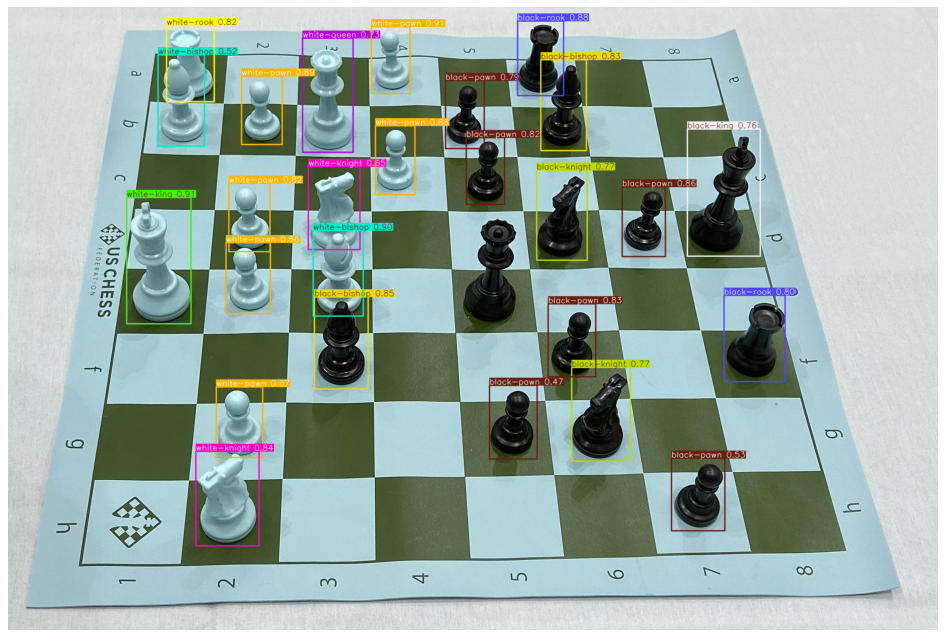

In [4]:
import matplotlib.pyplot as plt
image_test_path = '/Users/tushar/Documents/IIST/Sem-2/computer vision/Project/code/visual_mycode/data/real/000.jpg'
results = model.predict(source=image_test_path, imgsz=640)

test_image = results[0].plot(line_width=2)
plt.figure(figsize=(15, 15), dpi=80) 

plt.imshow(test_image)
plt.axis('off')
plt.show()

In [9]:
boxes = results[0].boxes.xyxy.cpu().numpy()      # (N, 4) format: [x1, y1, x2, y2]
scores = results[0].boxes.conf.cpu().numpy()     # confidence scores
labels = results[0].boxes.cls.cpu().numpy()

In [10]:
import numpy as np
import networkx as nx

# Compute centers
centers = np.array([[(x1 + x2) / 2, (y1 + y2) / 2] for x1, y1, x2, y2 in boxes])

# Create graph
G = nx.Graph()

# Add nodes with features
for i, (center, label, score) in enumerate(zip(centers, labels, scores)):
    G.add_node(i, feature=np.concatenate([center, [label], [score]]))  # example features

# Add edges based on distance threshold
dist_thresh = 100  # you can tune this
for i in range(len(centers)):
    for j in range(i + 1, len(centers)):
        dist = np.linalg.norm(centers[i] - centers[j])
        if dist < dist_thresh:
            G.add_edge(i, j, weight=1.0 / (dist + 1e-5))


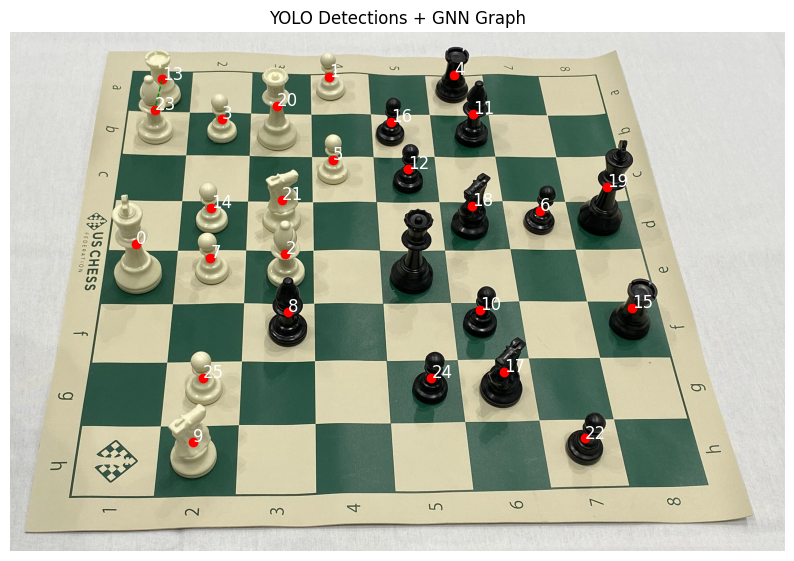

In [11]:
import matplotlib.pyplot as plt
import networkx as nx

# Visualize detections with graph edges
plt.figure(figsize=(10, 10))
img = plt.imread(image_test_path)
plt.imshow(img)
plt.axis('off')

# Plot bounding box centers
for idx, (x, y) in enumerate(centers):
    plt.plot(x, y, 'ro')  # red dot for each object
    plt.text(x, y, str(idx), color='white', fontsize=12)

# Draw edges between nodes
for i, j in G.edges():
    x1, y1 = centers[i]
    x2, y2 = centers[j]
    plt.plot([x1, x2], [y1, y2], 'g--', linewidth=1)

plt.title("YOLO Detections + GNN Graph")
plt.show()


In [36]:
import torch
import torch.nn as nn
import torch.optim as optim
from torch_geometric.data import Data
from sklearn.neighbors import NearestNeighbors
import matplotlib.pyplot as plt
import numpy as np

# Assuming 'centers' is a list of coordinates for the detected pieces
# e.g., [[x1, y1], [x2, y2], ...]
centers = np.array([[100, 200], [150, 250], [200, 300], [250, 350]])  # Example coordinates
NUM_CLASSES = 3  # Example number of classes (change based on your labels)

# 1. Define the node features (e.g., coordinates of the pieces)
features = centers  # For simplicity, using coordinates as features
features = torch.tensor(features, dtype=torch.float)  # Convert to tensor

# 2. Construct the edge_index using K-nearest neighbors
k_neighbors = 3  # Number of neighbors for each node

knn = NearestNeighbors(n_neighbors=k_neighbors, algorithm='auto')
knn.fit(centers)
distances, indices = knn.kneighbors(centers)

edges = []
for i, neighbors in enumerate(indices):
    for neighbor in neighbors:
        if i != neighbor:  # Avoid self-loops
            edges.append([i, neighbor])

# Convert the edge list to a tensor (2xN format)
edge_index = torch.tensor(edges, dtype=torch.long).t().contiguous()

# 3. Define labels for the nodes (pieces)
# Example: If you have 3 classes, labels could be random, or they could come from your data
labels = torch.tensor([0, 1, 2, 0], dtype=torch.long)  # Example labels

# 4. Create a Data object for PyTorch Geometric
data = Data(x=features, edge_index=edge_index, y=labels)

# 5. Define the GNN model for refinement
class GNNRefinementModel(nn.Module):
    def __init__(self, in_channels, hidden_channels, out_channels):
        super(GNNRefinementModel, self).__init__()
        self.conv1 = torch_geometric.nn.GCNConv(in_channels, hidden_channels)
        self.conv2 = torch_geometric.nn.GCNConv(hidden_channels, out_channels)

    def forward(self, x, edge_index):
        x = self.conv1(x, edge_index)
        x = torch.relu(x)
        x = self.conv2(x, edge_index)
        return x

# 6. Instantiate the model, optimizer, and loss function
model = GNNRefinementModel(in_channels=features.shape[1], hidden_channels=32, out_channels=NUM_CLASSES)
optimizer = optim.Adam(model.parameters(), lr=0.01)
criterion = nn.CrossEntropyLoss()

# 7. Training loop
for epoch in range(100):
    model.train()
    optimizer.zero_grad()
    out = model(data.x, data.edge_index)  # Forward pass
    loss = criterion(out[data.train_mask], data.y[data.train_mask])  # Compute loss (use mask for training nodes)
    loss.backward()
    optimizer.step()
    print(f"Epoch {epoch} | Loss: {loss.item():.4f}")

# 8. Visualize the refined detections on the board
plt.figure(figsize=(10, 10))
img = plt.imread('/path/to/your/image.jpg')  # Use your image path here
plt.imshow(img)
plt.axis('off')

# After training, plot the refined detections
model.eval()
with torch.no_grad():
    out = model(data.x, data.edge_index)
    _, predicted = torch.max(out, dim=1)  # Get the predicted class for each piece

# Visualize the pieces and their predicted labels
for i, (x, y) in enumerate(centers):
    plt.plot(x, y, 'go')  # Green dots for pieces
    plt.text(x, y, f'{predicted[i].item()}', color='white', fontsize=10)

plt.title("Refined Board Pieces (GNN)")
plt.show()


NameError: name 'torch_geometric' is not defined